# 03 Â· 3D scene and vertical scale

**Mission.** Use a 3D view to communicate priorities without letting visual height imply physical height.

![Illustrated OSIRIS VEOC mission board](assets/veoc-splash.svg)

> **Exercise only.** All sectors, calls, flood depths, beds, and travel times below are invented. Run each notebook independently with the **Python (Pyodide)** kernel in JupyterLite. First startup downloads the browser runtime. The linked OSIRIS console is a separate application.

[Book home](intro.md) Â· [2D operations map](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-2d.html) Â· [3D scene](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-3d.html) Â· [OSIRIS](https://osirisai.live/)

In [1]:
import math, json, statistics
from datetime import datetime, timezone
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Markdown
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False, "axes.spines.right": False})
SECTORS = [
 {"name":"Harbor", "lat":29.93,"lon":-90.07,"population":18000,"calls":34,"flood_m":0.9,"open_beds":12,"road_min":28,"reporting":0.84},
 {"name":"Eastbank","lat":29.96,"lon":-90.00,"population":24000,"calls":22,"flood_m":0.4,"open_beds":24,"road_min":19,"reporting":0.91},
 {"name":"Canal",   "lat":29.98,"lon":-90.10,"population":12000,"calls":31,"flood_m":1.4,"open_beds":4, "road_min":42,"reporting":0.68},
 {"name":"North",   "lat":30.05,"lon":-90.07,"population":30000,"calls":18,"flood_m":0.1,"open_beds":38,"road_min":14,"reporting":0.96},
 {"name":"Bayou",   "lat":29.89,"lon":-90.12,"population":9000, "calls":25,"flood_m":1.1,"open_beds":7, "road_min":51,"reporting":0.72},
 {"name":"Airport", "lat":30.00,"lon":-90.25,"population":16000,"calls":11,"flood_m":0.2,"open_beds":18,"road_min":23,"reporting":0.89},
]
for sector in SECTORS:
    sector["rate_10k"] = sector["calls"] / sector["population"] * 10000
print("EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied")

EXERCISE DATA â€” fictional sectors, observations and facilities; no real incident implied


The [interactive 3D scene](https://jltobias.github.io/JupyterLite-Osiris/scenes/operations-3d.html) extrudes **synthetic calls** over a dark basemap. It is a thematic scene, not terrain, a flood simulation, or satellite reconstruction. Rotate and zoom to see how perspective can obscure short columns. For real terrain context, compare [OSIRIS](https://osirisai.live/) and inspect its layer provenance.

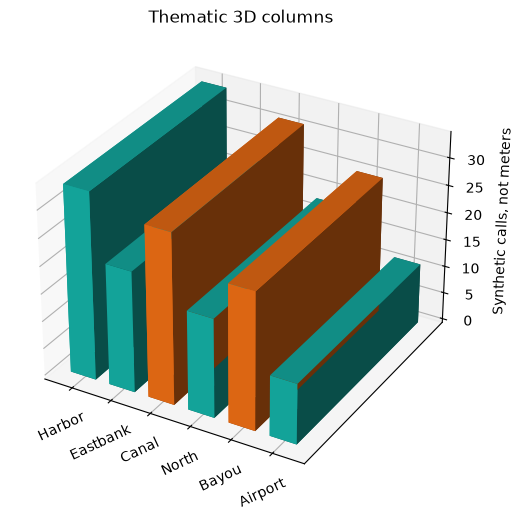

In [2]:
depth=np.array([s['flood_m'] for s in SECTORS]);calls=np.array([s['calls'] for s in SECTORS]);order=np.argsort(calls)[::-1]
fig=plt.figure(figsize=(9,6));ax=fig.add_subplot(projection='3d')
ax.bar3d(np.arange(len(SECTORS)),np.zeros(len(SECTORS)),np.zeros(len(SECTORS)),.65,.65,calls,color=['#f97316' if d>=1 else '#16b8ad' for d in depth],shade=True)
ax.set_xticks(np.arange(len(SECTORS))+.3,[s['name'] for s in SECTORS],rotation=25);ax.set_yticks([]);ax.set_zlabel('Synthetic calls, not meters');ax.set_title('Thematic 3D columns');plt.show()

In [3]:
for i in order[:3]: print(f"{SECTORS[i]['name']}: {calls[i]} calls; {depth[i]:.1f} m synthetic depth")

Harbor: 34 calls; 0.9 m synthetic depth
Canal: 31 calls; 1.4 m synthetic depth
Bayou: 25 calls; 1.1 m synthetic depth


## Field exercise and review
Explain which variable determines column height and which determines color. Identify a sector hidden from one viewing angle. Recheck the ranking in the printed table.

## Source desk
- [OSIRIS source and MIT license](https://github.com/simplifaisoul/osiris) Â· [OSIRIS live console](https://osirisai.live/)
- [USGS Earthquake API](https://earthquake.usgs.gov/fdsnws/event/1/) Â· [NASA EONET](https://eonet.gsfc.nasa.gov/docs/v3) Â· [NASA FIRMS](https://firms.modaps.eosdis.nasa.gov/)
- [NOAA National Hurricane Center](https://www.nhc.noaa.gov/) Â· [GDACS](https://www.gdacs.org/) Â· [OpenSky Network](https://opensky-network.org/)

**Use rule:** A source link provides context, not independent confirmation of this fictional exercise. Check timestamps, geography, provider terms, and incident command procedures before any real decision.